# Source model selection

Forced photometry is only as good as the source models it carries from VIS to the other bands:
the shape of each model decides how much light it collects and how blended light is divided
between neighbours. The MER catalog already gives every source a model, a point-likeness
probability and a VIS Sérsic fit, and the simplest choice is to use them as delivered
(`model_selection="prior"`). Those parameters come from MER's own fitting, with its own PSF model
and its own treatment of neighbours. Here the models are rendered by The Tractor with the MER PSF
samples and fitted jointly with their neighbours, and a MER shape that suited MER's fit need not
describe the VIS pixels well in this one. The model-selection tree refits every source on VIS
inside this fitting model and keeps the simplest profile that describes its pixels. Section 6
measures the difference on this field.

This notebook traces the tree on one blob of a 50 arcsec field.
[Notebook 01](../01_nisp_forced_photometry.ipynb) runs the same selector on every blob of its
field.

The tree adapts [The Farmer](https://ui.adsabs.harvard.edu/abs/2023ApJS..269...20W) (Weaver et al. 2023). It compares
point-source, fixed circular exponential, exponential, de Vaucouleurs, and
composite profiles by reduced chi-squared, stopping early when a point
source is sufficient. Bright resolved candidates also try a free-index
Sérsic profile, kept when the total chi-squared improves by more than 25.
VIS positions are refined within 0.3 arcsec.

The tree runs on VIS only. A fit with a NISP prior (`prior={"band": "H", "objects": "mer"}`)
starts from the MER models and refits their shapes on the NISP image instead;
[notebook 02](../02_wise_forced_photometry.ipynb) uses one for unWISE.

## 1. Imports, target, cutout, and PSF

In [1]:
# Locate the package when running from either notebook directory.
import os, sys
from pathlib import Path
PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / "src/euclid_phot").is_dir()), None)
if PROJECT_ROOT is None:
    raise RuntimeError("Run this notebook from the repository.")
if "euclid_phot" in sys.modules:
    loaded_from = Path(sys.modules["euclid_phot"].__file__).resolve()
    if loaded_from != (PROJECT_ROOT / "src/euclid_phot/__init__.py").resolve():
        raise RuntimeError("Restart the kernel to load this repository's package.")
sys.path.insert(0, str(PROJECT_ROOT / "src"))
os.environ.setdefault("EUCLID_PHOT_DATA_DIR", str(PROJECT_ROOT / "examples/native_data"))

import matplotlib.pyplot as plt
import numpy as np
from astropy.table import Table

import euclid_phot as ep

TARGET_RA = 269.48
TARGET_DEC = 67.30
CUTOUT_SIZE_ARCSEC = 50.0
DATA_DIR = Path(os.environ["EUCLID_PHOT_DATA_DIR"])


In [2]:
mer_path = DATA_DIR / f"mer_catalog_{TARGET_RA:.4f}_{TARGET_DEC:.4f}_{int(CUTOUT_SIZE_ARCSEC)}.fits"
if mer_path.exists():
    mer_cat = Table.read(mer_path)
else:
    half_size_deg = CUTOUT_SIZE_ARCSEC / 2.0 / 3600.0
    mer_cat = ep.query_mer_catalog(TARGET_RA, TARGET_DEC, half_size_deg)
vis = ep.fetch_cutout("VIS", TARGET_RA, TARGET_DEC, CUTOUT_SIZE_ARCSEC,
                      data_dir=DATA_DIR / "cutouts")
mer_cat = ep.trim_catalog_to_cutout(mer_cat, vis.wcs, vis.shape)
print(f"{len(mer_cat)} sources in the cutout")

psf_data = ep.extract_catalog_psf(
    "VIS", TARGET_RA, TARGET_DEC, radius_arcsec=60.0,
    tile_id=vis.header.get("MERTILE"), data_dir=DATA_DIR / "psf")
tim_vis = ep.build_tractor_image(vis, psf_data=psf_data)

63 sources in the cutout


## 2. Blob detection

SEP detects sources in the background-subtracted image at a filtered
1.5-sigma threshold with a minimum area of five pixels. Growing the
segments by four pixels groups nearby detections into blobs, and the MER
sources inside a blob are fitted together.

In [3]:
blobs, _, _ = ep.detect_blobs(
    vis.data, tim_vis.getInvvar(),
    threshold_sigma=1.5, minarea=5, dilate_pix=4)
blobs = ep.assign_mer_to_blobs(mer_cat, blobs, tim_vis.getWcs())
blobs_with_sources = [b for b in blobs if b.member_mer_indices]
print(f"blobs with at least one MER source: {len(blobs_with_sources)}")

blobs with at least one MER source: 50


## 3. Run the tree on one two-source blob

The example is the brightest pair with both members below 50 microJansky. Change
`target_blob` to inspect another case.

In [4]:
_flux = np.ma.filled(np.ma.asarray(mer_cat['flux_vis_psf'], float), 0.0)
pairs = [b for b in blobs_with_sources
         if len(b.member_mer_indices) == 2
         and all(_flux[i] < 50.0 for i in b.member_mer_indices)]
_pair_flux = lambda b: sum(_flux[i] for i in b.member_mer_indices)
target_blob = (max(pairs, key=_pair_flux) if pairs
               else blobs_with_sources[0])
print(f"using blob {target_blob.blob_id} with members {target_blob.member_mer_indices}")


using blob 78 with members [3, 9]


In [5]:
selector = ep.ModelSelector(
    sufficient_thresh=1.5,
    simplegalaxy_penalty=0.05,
    exp_dev_similar_thresh=0.15,
    simplegalaxy_radius=0.30,
)
chosen, history = selector.fit_blob(
    target_blob, tim_vis, mer_cat, vis.pixel_scale_arcsec,
    history=True,
)
for i, src in chosen.items():
    print(f"MER {i} -> {type(src).__name__}")


MER 3 -> SersicGalaxy
MER 9 -> PointSource


## 4. The scores and the selected models

One line per trial: the reduced chi-squared of each candidate profile and
whether the tree accepted it.

In [6]:
print(f"{'MER':>4s} {'stage':>5s} {'model':<22s} {'chi2_red':>9s} {'accepted':>9s}")
by_idx_stage = {(r.source_idx, r.stage): r for r in history.stages}
for idx in target_blob.member_mer_indices:
    for s in sorted({s for (_, s) in by_idx_stage}):
        rec = by_idx_stage.get((idx, s))
        if rec is None:
            continue
        print(f"{idx:>4d} {s:>5d} {rec.model_name:<22s} "
              f"{rec.chi2_red:>9.2f} {'YES' if rec.accepted else '':>9s}")


 MER stage model                   chi2_red  accepted
   3     1 SimpleGalaxy                7.26          
   3     2 PointSource                20.60          
   3     3 ExpGalaxy                   5.26          
   3     4 DevGalaxy                   0.72          
   3     5 CompositeGalaxy             1.04          
   3     6 SersicGalaxy(n=5.27)        0.46       YES
   9     1 SimpleGalaxy               10.03          
   9     2 PointSource                 0.53       YES


## 5. The profile trials

Each row shows a trial model and its residual, neighbouring sources
included. The image stretch uses the residual noise outside the blob; the
tabulated chi-squared uses the pixel weights.

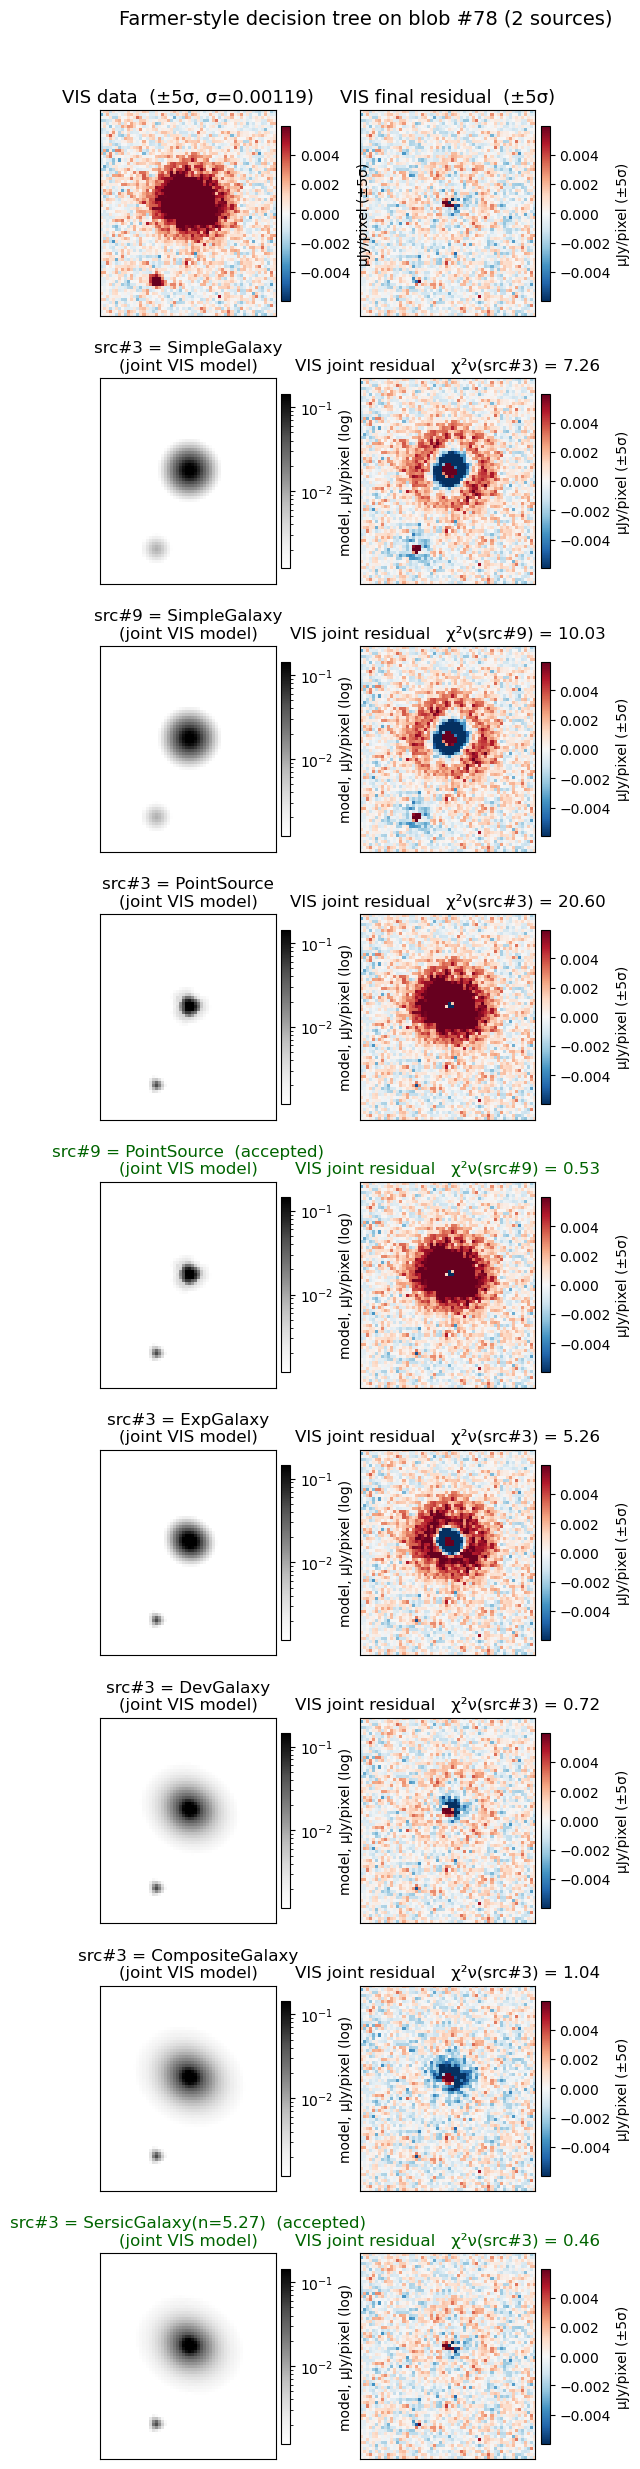

In [7]:
fig, _ = ep.reproduce_figure3(target_blob, history,
                             flux_scale=ep.viz.ujy_per_unit(vis), unit="µJy/pixel")
plt.show()


## 6. The whole field: MER models against the tree

The cells below fit the VIS fluxes of every source in the field twice: once with the MER models
as delivered, and once with the models the tree chooses on every blob. Both fits render the models
with the same PSF samples, fit all fluxes together, and leave out the bright-star pixels as
notebook 01 does; a star's halo is light the PSF stamps cannot model, and either set of models
would otherwise distort to absorb it. The chi-squared summed over the pixels of each blob
measures how well each set of models describes that part of the VIS image.

In [8]:
from collections import Counter

# The FLG plane gives the STARSIGNAL bright-star footprints.
vis_flag = ep.fetch_cutout("VIS", TARGET_RA, TARGET_DEC, CUTOUT_SIZE_ARCSEC,
                           data_dir=DATA_DIR / "cutouts", with_flag=True)
tim_masked = ep.build_tractor_image(vis_flag, psf_data=psf_data,
                                    pixel_mask=ep.starsignal_pixel_mask(vis_flag))
invvar = tim_masked.getInvvar()

psf_fwhm = float(np.median(psf_data["fwhm"]))
mer_models = ep.build_sources_from_mer(mer_cat, band="VIS", psf_fwhm_arcsec=psf_fwhm)
tree_list, _ = ep.run_model_selection(
    mer_cat, tim_masked, vis_flag.data, invvar,
    pixscale_arcsec=vis.pixel_scale_arcsec, n_workers=4)
tree_models = [s if s is not None else fb for s, fb in zip(tree_list, mer_models)]

initial_ujy = np.asarray(mer_cat["flux_vis_sersic"], float)
chi = {}
for label, models in (("MER models", mer_models), ("tree models", tree_models)):
    tractor, _ = ep.fit_forced_photometry(tim_masked, models, band="VIS",
                                          initial_fluxes_ujy=initial_ujy)
    chi[label] = tractor.getChiImage(0)
    classes = Counter(type(s).__name__ for s in models)
    print(f"{label}: " + ", ".join(f"{k} {v}" for k, v in classes.most_common()))

# Chi-squared per blob with each set of models.
rows = []
for b in blobs_with_sources:
    pix = b.footprint & (invvar > 0)
    chi2_mer, chi2_tree = (float(np.sum(chi[k][pix] ** 2)) for k in chi)
    rows.append((chi2_mer - chi2_tree, b, float(initial_ujy[b.member_mer_indices].sum())))
gain = np.array([r[0] for r in rows])
flux = np.array([r[2] for r in rows])
bright = flux > 5.0
print(f"\nchi2 reduction over all {len(rows)} blobs: {gain.sum():.0f}")
print(f"the {bright.sum()} blobs above 5 uJy: {gain[bright].sum():.0f} "
      f"({100 * gain[bright].sum() / gain.sum():.0f}%)")
print(f"the {(~bright).sum()} fainter blobs: median change {np.median(gain[~bright]):+.1f}, "
      f"{int(np.sum(gain[~bright] < 0))} slightly worse with the tree")

MER models: SersicGalaxy 57, PointSource 6


tree models: ExpGalaxy 29, PointSource 14, DevGalaxy 9, SersicGalaxy 7, FixedCompositeGalaxy 4

chi2 reduction over all 50 blobs: 1532
the 4 blobs above 5 uJy: 1574 (103%)
the 46 fainter blobs: median change +0.2, 21 slightly worse with the tree


The three blobs where the two sets of models differ most, ordered by the reduction in
chi-squared. Each row shows the VIS data and the residual divided by the pixel noise with each set
of models; the title gives each member's MER model and tree model.

row 1: chi2 reduction 1280; MER 0: PointSource -> PointSource; MER 4: SersicGalaxy -> SersicGalaxy
row 2: chi2 reduction 182; MER 1: PointSource -> PointSource
row 3: chi2 reduction 113; MER 3: SersicGalaxy -> SersicGalaxy; MER 9: PointSource -> PointSource


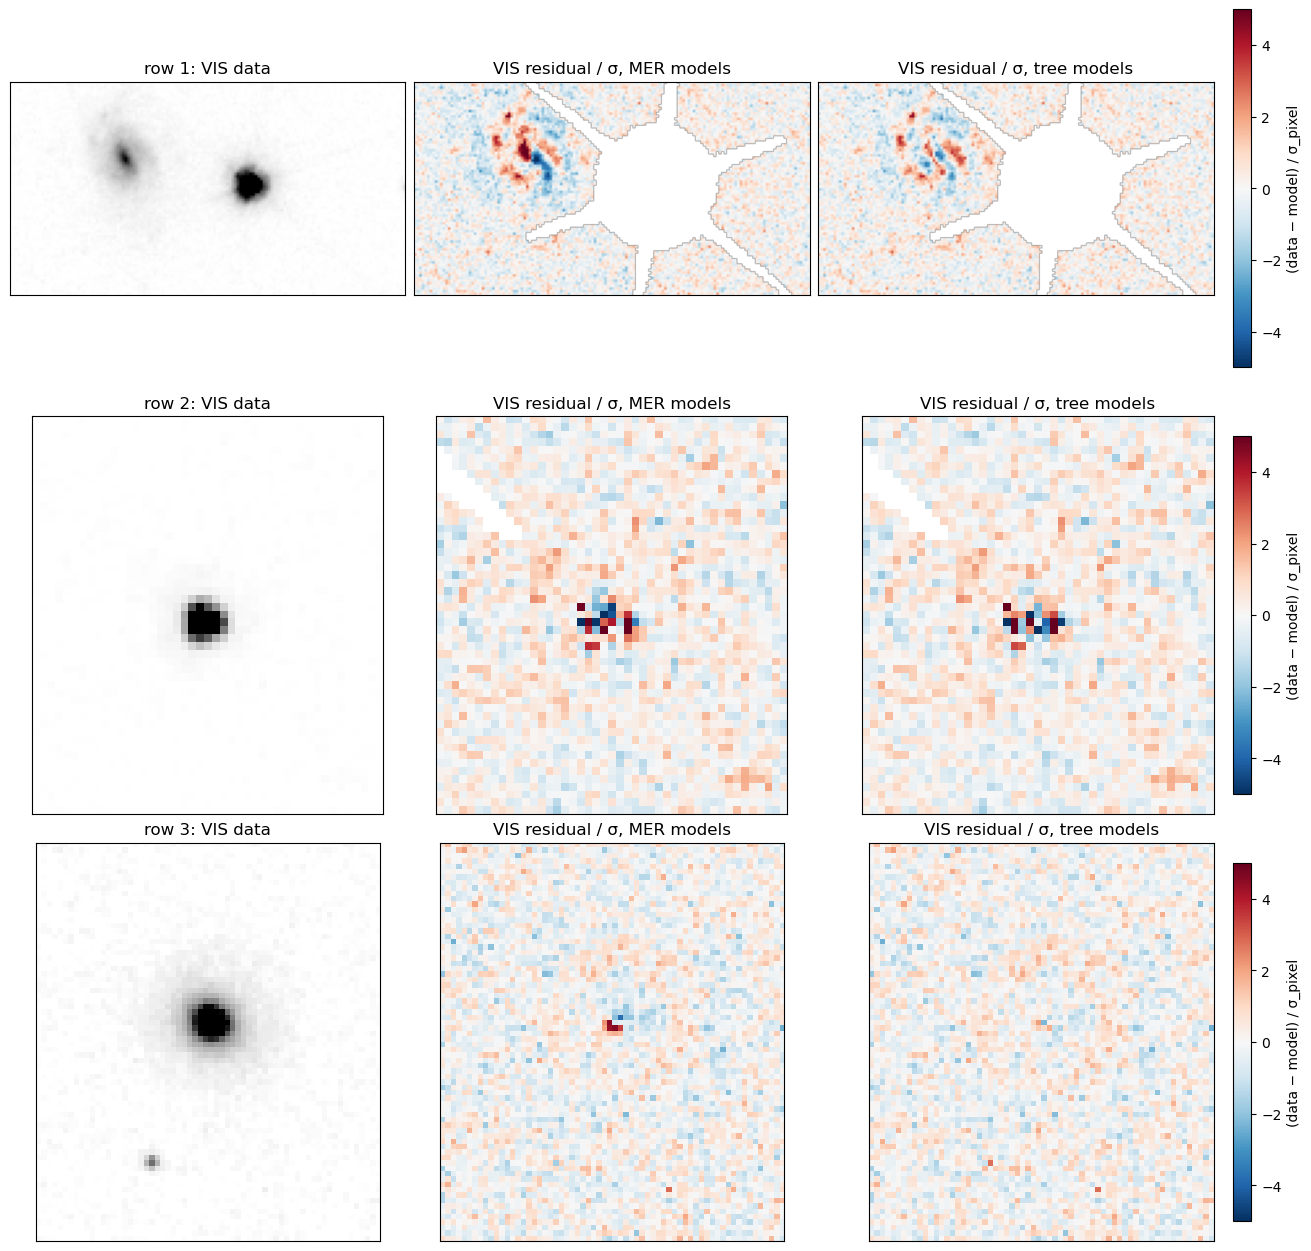

In [9]:
top = sorted(rows, key=lambda r: -r[0])[:3]
for k, (dchi2, blob, _) in enumerate(top, 1):
    members = "; ".join(f"MER {i}: {type(mer_models[i]).__name__} -> {type(tree_models[i]).__name__}"
                        for i in blob.member_mer_indices)
    print(f"row {k}: chi2 reduction {dchi2:.0f}; {members}")

UJY = ep.viz.ujy_per_unit(vis)
fig, axes = plt.subplots(len(top), 3, figsize=(13, 4.2 * len(top)), squeeze=False,
                         constrained_layout=True)
for k, (row, (dchi2, blob, _)) in enumerate(zip(axes, top), 1):
    yy, xx = np.nonzero(blob.footprint)
    pad = 8
    sl = np.s_[max(yy.min() - pad, 0):yy.max() + pad + 1,
               max(xx.min() - pad, 0):xx.max() + pad + 1]
    stamp = vis_flag.data[sl] * UJY
    row[0].imshow(stamp, origin="lower", cmap="gray_r", vmin=0,
                  vmax=np.nanpercentile(stamp, 99.5))
    row[0].set_title(f"row {k}: VIS data")
    for ax, label in zip(row[1:], chi):
        shown = np.where(invvar[sl] > 0, chi[label][sl], np.nan)
        im = ax.imshow(shown, origin="lower", cmap="RdBu_r", vmin=-5, vmax=5)
        ax.set_title(f"VIS residual / σ, {label}")
    fig.colorbar(im, ax=row[2], label="(data − model) / σ_pixel", shrink=0.9)
    for ax in row:
        ax.set_xticks([]); ax.set_yticks([])
plt.show()

*The VIS data and the residual divided by the pixel noise with the MER models and with the
tree's models, for the three blobs with the largest reduction in chi-squared. Masked bright-star
pixels are blank.*

On this field the whole reduction comes from the few galaxies brighter than about 5 microJansky.
In each of the three blobs above, the tree keeps the profile class MER assigned; the gain comes
from fitting the shape, and the position within 0.3 arcsec, in the same model and with the same
PSF that the forced photometry uses. Neither set of smooth profiles reproduces the spiral arms
in row 1. For faint sources the two sets of models describe the VIS
pixels equally well, and the tree does slightly worse on some.

This sets the practical choice. The MER models cost one linear solve and are adequate for faint,
isolated sources. The tree is worth its time and memory (README, "Computing cost") when bright or
blended galaxies matter, because the models decide how flux is divided between neighbours in
NISP, unWISE, and IRAC, where the sources overlap more.